In [1]:
import copy
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from torch import nn
from torch.utils.data import TensorDataset, DataLoader
from torchvision.models import resnet18, ResNet18_Weights
from sklearn.metrics import balanced_accuracy_score
from utiles import read_frames, preprocess, MEAN, STD, N_FRAMES

torch.manual_seed(0)
df = pd.read_csv("index.csv")
device = "cuda" if torch.cuda.is_available() else "cpu"

def frames_of(split):
    part = df[df.split == split]
    x = np.concatenate([read_frames(p) for p in part.path])   # (клипы*16, 224, 224, 3) uint8
    y = np.repeat(part.label.values, N_FRAMES)                 # метка клипа -> каждому кадру
    return torch.from_numpy(x), torch.from_numpy(y)

x_tr, y_tr = frames_of("train")
x_va, y_va = frames_of("val")
print(x_tr.shape, x_va.shape)

torch.Size([2576, 224, 224, 3]) torch.Size([496, 224, 224, 3])


In [2]:
def to_input(x_uint8):
    x = x_uint8.permute(0, 3, 1, 2).float().div(255)
    return ((x - MEAN) / STD).to(device)

train_dl = DataLoader(TensorDataset(x_tr, y_tr), batch_size=32, shuffle=True)
val_dl = DataLoader(TensorDataset(x_va, y_va), batch_size=64)

model = resnet18(weights=ResNet18_Weights.IMAGENET1K_V1)
model.fc = nn.Linear(512, 2)                      # новый выходной слой на 2 класса
for name, p in model.named_parameters():          # учим только последний блок и fc
    p.requires_grad = name.startswith(("layer4", "fc"))
model.to(device)

counts = np.bincount(y_tr.numpy())                # веса классов против дисбаланса
weights = torch.tensor(counts.sum() / (2 * counts), dtype=torch.float32, device=device)
criterion = nn.CrossEntropyLoss(weight=weights)
optimizer = torch.optim.SGD([p for p in model.parameters() if p.requires_grad],
                            lr=1e-3, momentum=0.9)

In [3]:
EPOCHS = 10
best_score, best_state, history = -1, None, []

for epoch in range(EPOCHS):
    model.train()
    tr_loss = 0
    for x, y in train_dl:
        x = to_input(x)
        if torch.rand(1) < 0.5:                   # аугментация: зеркальное отражение
            x = x.flip(3)
        y = y.to(device)
        optimizer.zero_grad()
        loss = criterion(model(x), y)
        loss.backward()
        optimizer.step()
        tr_loss += loss.item() * len(y)

    model.eval()
    va_loss, preds = 0, []
    with torch.no_grad():
        for x, y in val_dl:
            out = model(to_input(x))
            va_loss += criterion(out, y.to(device)).item() * len(y)
            preds.append(out.argmax(1).cpu())
    score = balanced_accuracy_score(y_va, torch.cat(preds))
    history.append((tr_loss / len(y_tr), va_loss / len(y_va), score))
    print(f"epoch {epoch+1}: train loss {history[-1][0]:.3f}, "
          f"val loss {history[-1][1]:.3f}, val bal acc {score:.3f}")

    if score > best_score:                        # запоминаем лучшую эпоху по val
        best_score, best_state = score, copy.deepcopy(model.state_dict())

epoch 1: train loss 0.494, val loss 0.666, val bal acc 0.573
epoch 2: train loss 0.181, val loss 0.742, val bal acc 0.641
epoch 3: train loss 0.087, val loss 0.816, val bal acc 0.610
epoch 4: train loss 0.043, val loss 0.905, val bal acc 0.610
epoch 5: train loss 0.033, val loss 0.938, val bal acc 0.610
epoch 6: train loss 0.024, val loss 0.940, val bal acc 0.598
epoch 7: train loss 0.017, val loss 0.997, val bal acc 0.614
epoch 8: train loss 0.009, val loss 0.996, val bal acc 0.601
epoch 9: train loss 0.010, val loss 1.031, val bal acc 0.602
epoch 10: train loss 0.008, val loss 1.085, val bal acc 0.591


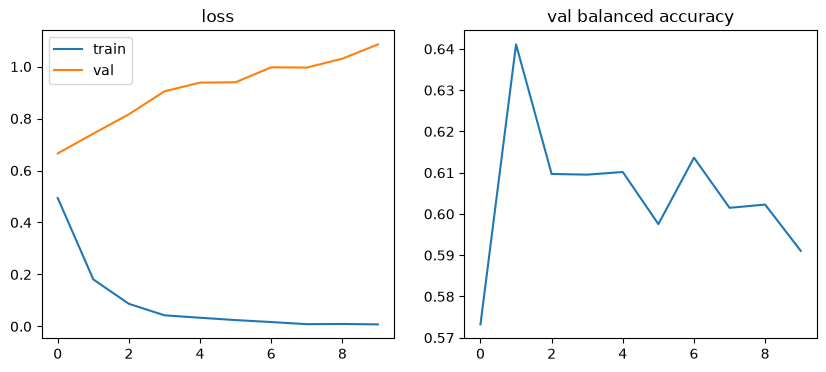

In [5]:
h = np.array(history)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 4))
a1.plot(h[:, 0], label="train"); a1.plot(h[:, 1], label="val"); a1.set_title("loss"); a1.legend()
a2.plot(h[:, 2]); a2.set_title("val balanced accuracy")
plt.show()

In [6]:
model.load_state_dict(best_state)
torch.save(model.state_dict(), "resnet18_ft.pt")   # пригодится для камеры

model.fc = nn.Identity()
model.eval()
feats = []
with torch.no_grad():
    for path in df.path:
        feats.append(model(preprocess(read_frames(path)).to(device)).cpu().numpy())
feats = np.stack(feats)
np.save("features_ft.npy", feats)
print(feats.shape)   # (272, 16, 512)

(272, 16, 512)
